# SinhalaMMLU — Test-set EDA

Exploratory analysis of the question files in `data/SinhalaMMLU/TEST/<level>/`
(one JSON file per subject, official schema:
`q_no, subject, category, question, choices, answer, metadata{subject_original, difficulty, grade, type, year, source}`).

**Questions this notebook answers**

| § | Question | Why it matters |
|---|---|---|
| 1 | Is the data well-formed? | Your inference pipeline must survive every record and echo the right keys into `predictions.jsonl`. |
| 2 | What is in it? | Subjects, categories, grades and exam sources — and where the questions were scraped from. |
| 3 | What do the options look like? | Option count, duplicates, self-numbered options, label-combination options (`ABCD`, `A හා C`). |
| 4 | Where do the correct options sit? | Position skew in the answer key: what a constant guess scores, and the bar your model must clear. |
| 5 | How long are the questions? | Sets `max_seq_len`, batch size and runtime. |
| 6 | Is the Sinhala text clean? | NFC, ZWJ/ZWNJ, conjunct conventions, broken text — the training corpus must use the same encoding. |
| 7 | Which hard question types are present? | Negation, multi-statement, figure references, … — known weak spots. |
| 8 | Duplicates and overlap | Duplicates inside the set, and overlap with another set (e.g. the Codabench test file). |
| 9 | Token lengths (optional) | Prompt length and Sinhala fertility per candidate tokenizer. |

**Ground rules** (shared-task Rules §4 and Integrity)

- *"Training, tuning or prompt design on test questions in any form is strictly prohibited."* Use these findings
  only for **pipeline robustness, compute budgeting and decontamination**. Make prompt, hyperparameter and
  data-mix decisions on the **dev set**.
- Gold answers are **dropped on load**. Only §4 touches them, re-reading them from the files for a distribution check
  on the public split you already have; no answer reaches `df`, a prompt or a model. Using test answers to train, tune
  or decide anything is grounds for disqualification.
- The test set is licensed for the shared task only. Do not commit the data or this notebook's executed outputs
  to a public repo — clear outputs first (`pip install nbstripout && nbstripout --install` does it on every commit).

Requirements: `pandas`, `matplotlib`; optional `transformers` for §9. Run from the project root or from `notebooks/`.

In [ ]:
import json
import re
import unicodedata
from collections import Counter
from pathlib import Path 
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# ---- Configuration: the only cell you should need to edit -------------------
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LEVEL = "easy"                                    # easy | medium | hard
DATA_DIR = PROJECT_ROOT / "data" / "SinhalaMMLU" / "TEST" / LEVEL
COMPARE_PATH = None                               # optional file or folder for the overlap check in §8,
                                                  # e.g. PROJECT_ROOT / "data" / "codabench" / "test.jsonl"
EXPECTED_N_CHOICES = 4                            # shared task: 4 options at EVERY level (Hard had one distractor dropped)
PUBLIC_EASY_SPLIT_SIZE = 1851                     # HF naist-nlp/SinhalaMMLU public Easy split (1,893 - 14 subjects x 3 few-shot)
PAPER_MEAN_CHARS = {                              # SinhalaMMLU paper / repo README: (question, answer) mean length in characters
    "easy": (59.08, 16.77), "medium": (100.66, 24.79), "hard": (116.40, 27.53),
}
REPORT_DIR = PROJECT_ROOT / "reports" / "eda"
TOKENIZERS = {                                    # optional (§9); set to {} to skip
    "Qwen3.5-4B-Base": "Qwen/Qwen3.5-4B-Base",
    "Gemma-3-4B-it": "google/gemma-3-4b-it",      # gated: accept the licence and `huggingface-cli login` first
}

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold",
})
BAR_COLOR = "#3A6EA5"

findings: dict[str, object] = {}                  # key numbers collected section by section, summarised in §10

### Helpers

Sinhala-specific rules used throughout:

- A **dependent vowel sign or al-lakuna (`්`) must follow a consonant**. One that doesn't ("orphan") means broken text — typically a legacy-font conversion error.
- A **ZWJ (U+200D) is only valid right after al-lakuna** (rakaransaya `ක්‍ර`, yansaya `ක්‍ය`, repaya `ර්‍ක`). Anywhere else it is stray.
- Keyword search runs on text with zero-width characters removed, so `සාවද්‍ය` matches whether or not the ZWJ is present.
- Patterns are written with `\u` escapes so invisible characters never hide in the source code.

In [29]:
SINHALA_CHAR = re.compile(r"[\u0D80-\u0DFF]")
CONSONANT = "\u0D9A-\u0DC6"
AL_LAKUNA = "\u0DCA"
DEPENDENT_SIGN = "\u0DCA\u0DCF-\u0DDF\u0DF2\u0DF3"            # al-lakuna + dependent vowel signs
ZERO_WIDTH = re.compile("[\u200B-\u200D]")                      # ZWSP, ZWNJ, ZWJ

ORPHAN_SIGN = re.compile(f"(?<![{CONSONANT}])[{DEPENDENT_SIGN}]")
STRAY_ZWJ = re.compile(f"(?<!{AL_LAKUNA})\u200D")
INVISIBLE_CHARS = {
    "ZWJ (U+200D)": "\u200D", "ZWNJ (U+200C)": "\u200C", "ZWSP (U+200B)": "\u200B",
    "NBSP (U+00A0)": "\u00A0", "BOM (U+FEFF)": "\uFEFF", "soft hyphen (U+00AD)": "\u00AD",
}
CONVENTIONS = {                                                  # approximate: some sequences match two patterns
    "repaya with ZWJ (ර්\u200Dක)": re.compile(f"\u0DBB{AL_LAKUNA}\u200D[{CONSONANT}]"),
    "repaya without ZWJ (ර්ක)": re.compile(f"\u0DBB{AL_LAKUNA}[{CONSONANT}]"),
    "rakaransaya with ZWJ (ක්\u200Dර)": re.compile(f"[{CONSONANT}]{AL_LAKUNA}\u200D\u0DBB"),
    "rakaransaya without ZWJ (ක්ර)": re.compile(f"[{CONSONANT}]{AL_LAKUNA}\u0DBB"),
    "yansaya with ZWJ (ක්\u200Dය)": re.compile(f"[{CONSONANT}]{AL_LAKUNA}\u200D\u0DBA"),
    "yansaya without ZWJ (ක්ය)": re.compile(f"[{CONSONANT}]{AL_LAKUNA}\u0DBA"),
}


def strip_zero_width(text: str) -> str:
    """Remove ZWJ/ZWNJ/ZWSP so keyword search works whatever the conjunct encoding."""
    return ZERO_WIDTH.sub("", text)


def normalise_key(text: str) -> str:
    """Canonical form for duplicate and overlap detection (NFC, no zero-width chars, collapsed spaces, lower case)."""
    text = strip_zero_width(unicodedata.normalize("NFC", text))
    return re.sub(r"\s+", " ", text).strip().lower()


def sinhala_ratio(text: str) -> float:
    """Share of visible characters (no whitespace, no zero-width chars) that are Sinhala."""
    visible = [ch for ch in strip_zero_width(text) if not ch.isspace()]
    return sum(bool(SINHALA_CHAR.match(ch)) for ch in visible) / max(len(visible), 1)


def pattern_counts(texts: pd.Series, pattern: re.Pattern) -> dict[str, int]:
    """Number of texts with at least one match, and total number of matches."""
    hits = texts.map(lambda t: len(pattern.findall(t)))
    return {"questions": int((hits > 0).sum()), "occurrences": int(hits.sum())}


def show_examples(mask: pd.Series, columns: list[str], n: int = 3) -> None:
    """Print how many rows match and display the first `n` of them."""
    print(f"{int(mask.sum())} matching question(s)")
    if mask.any():
        display(df.loc[mask, columns].head(n))


def barh(series: pd.Series, title: str, xlabel: str, fmt: str = "{:,.0f}") -> None:
    """Horizontal bar chart, largest bar on top, value printed next to each bar."""
    s = series.sort_values()
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(s) + 1.2))
    ax.barh(s.index.astype(str), s.values, color=BAR_COLOR, height=0.7)
    ax.bar_label(ax.containers[0], fmt=fmt, padding=3, fontsize=9)
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()

### Load

Every file under `DATA_DIR` is read as UTF-8 (Windows' default `cp1252` would corrupt Sinhala) and flattened into one
row per question. The `answer` field is **not kept** — only a `has_answer` flag, so §1 can tell you whether the files
carry gold labels. §4 reads the answers back from the files on its own, so no gold label can leak into a prompt
built from `df`.

In [30]:
def read_records(path: Path) -> list[dict]:
    """Read a JSON array (.json) or JSON Lines (.jsonl) file of question records."""
    with path.open(encoding="utf-8") as f:
        if path.suffix == ".jsonl":
            return [json.loads(line) for line in f if line.strip()]
        data = json.load(f)
    if not isinstance(data, list):
        raise ValueError(f"{path.name}: expected a JSON array of questions, got {type(data).__name__}")
    return data


def load_questions(path: Path) -> pd.DataFrame:
    """Load one question file, or every *.json / *.jsonl file in a folder, into a flat DataFrame without answers."""
    path = Path(path)
    files = [path] if path.is_file() else sorted(path.glob("*.json*"))
    if not files:
        raise FileNotFoundError(f"No .json/.jsonl files found at {path}")
    rows = []
    for file in files:
        for record in read_records(file):
            metadata = record.get("metadata") or {}
            rows.append({
                "file": file.name,
                "q_no": record.get("q_no"),
                "subject": record.get("subject"),
                "category": record.get("category"),
                "question": record.get("question"),
                "choices": record.get("choices"),
                "has_answer": record.get("answer") not in (None, ""),
                **{f"meta_{key}": value for key, value in metadata.items()},
            })
    return pd.DataFrame(rows)


df = load_questions(DATA_DIR)

# Defensive typing so one malformed record cannot break every later cell.
df["question"] = df["question"].fillna("").astype(str)
df["choices"] = df["choices"].map(lambda c: [str(x) for x in c] if isinstance(c, list) else [])
df["n_choices"] = df["choices"].str.len()
df["all_text"] = df["question"] + "\n" + df["choices"].str.join("\n")

findings["questions"] = len(df)
findings["files"] = df["file"].nunique()
findings["subjects"] = df["subject"].nunique()
print(f"{len(df):,} questions | {df['file'].nunique()} files | {df['subject'].nunique()} subjects | level = {LEVEL}")
print("Columns:", list(df.columns))
display(df.drop(columns=["all_text"]).head(3))

1,851 questions | 14 files | 17 subjects | level = easy
Columns: ['file', 'q_no', 'subject', 'category', 'question', 'choices', 'has_answer', 'meta_subject_original', 'meta_difficulty', 'meta_grade', 'meta_type', 'meta_year', 'meta_source', 'n_choices', 'all_text']


,file,q_no,subject,category,question,choices,has_answer,meta_subject_original,meta_difficulty,meta_grade,meta_type,meta_year,meta_source,n_choices
0,Arts_humanities_easy_f_97.json,1,Arts,humanities,"වෙසක් උත්සවයේදී බෞද්ධයින් අනුගමනය කරන පූජා විධි දෙක නම්,","[ආමිස පූජා සහ ප්‍රතිපත්ති පූජා, මල් පූජා හා පහන් පූජා, ද්‍රව්‍ය පූජා සහ භාණ්...",True,චිත්‍ර,easy,6,P_NWP_3,2022,https://pastpapers.wiki/2022-grade-06-art-3rd-term-test-paper-with-answers-n...,4
1,Arts_humanities_easy_f_97.json,2,Arts,humanities,හින්දු භක්තිකයින්ගේ ප්‍රධාන ආගමික උත්සවයකි.,"[නත්තල් උත්සවය, රාමසාන් උත්සවය, තෛපොංගල් උත්සවය, හජ්ජි උත්සවය]",True,චිත්‍ර,easy,6,P_NWP_3,2022,https://pastpapers.wiki/2022-grade-06-art-3rd-term-test-paper-with-answers-n...,4
2,Arts_humanities_easy_f_97.json,3,Arts,humanities,ඉස්ලාම් භක්තිකයින් රාමසාන් මාසයේ මුල් සඳ දුටු තැන් සිට අරඹන උපවාසය අවසන් කරන...,"[නව සඳ දැකීමෙන් පසුව ය., හිරු උදාව සමගය., නව හිරු දැකීමෙන් පසුව ය., සඳ බැස ග...",True,චිත්‍ර,easy,6,P_NWP_3,2022,https://pastpapers.wiki/2022-grade-06-art-3rd-term-test-paper-with-answers-n...,4


## 1. Schema and integrity

`(subject, q_no)` is the key you echo into `predictions.jsonl`. `q_no` restarts at 1 in every subject file, so it is
**not** unique on its own. Also note the type of `q_no` here (int vs str) and keep it consistent in your submission.

In [31]:
difficulty_mismatch = (
    int((df["meta_difficulty"].astype(str).str.lower() != LEVEL).sum())
    if "meta_difficulty" in df else "n/a (no metadata.difficulty)"
)

integrity = pd.Series({
    "empty question": int((df["question"].str.strip() == "").sum()),
    "choices missing or empty": int((df["n_choices"] == 0).sum()),
    "missing subject": int(df["subject"].isna().sum()),
    "missing category": int(df["category"].isna().sum()),
    "duplicate (subject, q_no) keys": int(df.duplicated(["subject", "q_no"]).sum()),
    f"metadata.difficulty != '{LEVEL}'": difficulty_mismatch,
    "questions carrying a gold answer": int(df["has_answer"].sum()),
}, name="count")
display(integrity.to_frame())
findings.update(integrity.to_dict())

print("q_no types:", df["q_no"].map(lambda v: type(v).__name__).value_counts().to_dict())

if df["has_answer"].any():
    print(
        f"\nWARNING: {int(df['has_answer'].sum()):,} of {len(df):,} questions carry a gold answer (dropped on load).\n"
        "The Codabench hidden test set is released WITHOUT answers, so this folder is not that file. It is most\n"
        "likely the public Hugging Face split. If its questions overlap the hidden test set (check with §8), do not\n"
        "use these answers for anything - not even validation - and confirm with the organisers."
    )

,count
empty question,0
choices missing or empty,0
missing subject,0
missing category,0
"duplicate (subject, q_no) keys",0
metadata.difficulty != 'easy',0
questions carrying a gold answer,1851


q_no types: {'int': 1851}

The Codabench hidden test set is released WITHOUT answers, so this folder is not that file. It is most
likely the public Hugging Face split. If its questions overlap the hidden test set (check with §8), do not
use these answers for anything - not even validation - and confirm with the organisers.


**Per-file consistency.** File names look like `<Subject>_<category>_<level>_f_<n>.json`. Check that the count `n`
matches the content, that the category in the name agrees with the `category` field (the field is what goes into
`predictions.jsonl`), and that `q_no` runs 1…n without gaps.

In [32]:
FILE_NAME = re.compile(r"^(?P<stem>.+)_(?P<level>easy|medium|hard)_f_(?P<n>\d+)$")

file_rows = []
for file, group in df.groupby("file"):
    name = Path(file).stem
    match = FILE_NAME.match(name)
    category = group["category"].iloc[0]
    q_numbers = pd.to_numeric(group["q_no"], errors="coerce")
    file_rows.append({
        "file": file,
        "questions": len(group),
        "subject": group["subject"].iloc[0],
        "category": category,
        "subjects_in_file": group["subject"].nunique(),
        "count_matches_name": int(match["n"]) == len(group) if match else None,
        "category_in_name": str(category).lower() in name.lower(),
        "q_no_is_1_to_n": sorted(q_numbers.tolist()) == list(range(1, len(group) + 1)),
    })
per_file = pd.DataFrame(file_rows).set_index("file")
display(per_file)

problems = per_file[(per_file["subjects_in_file"] != 1) | (per_file["count_matches_name"] == False)  # noqa: E712
                    | ~per_file["category_in_name"] | ~per_file["q_no_is_1_to_n"]]
findings["files with a naming/consistency problem"] = len(problems)
print(f"{len(problems)} file(s) with a consistency problem:", list(problems.index))

,questions,subject,category,subjects_in_file,count_matches_name,category_in_name,q_no_is_1_to_n
file,,,,,,,
Arts_humanities_easy_f_97.json,100,Arts,humanities,1,False,True,True
Buddhism_humanities_easy_f_162.json,162,Buddhism,humanities,1,True,True,True
Catholicism_humanities_easy_f_132.json,132,Catholicism,humanities,1,True,True,True
Christianity_humanities_easy_f_130.json,130,Christianity,humanities,1,True,True,True
Civics_social_science_easy_f_129.json,123,Civics,social_science,1,False,True,True
Eastern_music_humanities_easy_f_143.json,143,Eastern_music,humanities,2,True,True,True
Geography_social_science_easy_f_117.json,117,Geography,social_science,1,True,True,False
Health_and_Physical_Science_social_science_easy_f_130.json,130,Health and Physical Science,social_science,1,True,True,True
History_social_science_easy_f_151.json,151,History,humanities,1,True,False,True


8 file(s) with a consistency problem: ['Arts_humanities_easy_f_97.json', 'Civics_social_science_easy_f_129.json', 'Eastern_music_humanities_easy_f_143.json', 'Geography_social_science_easy_f_117.json', 'History_social_science_easy_f_151.json', 'Sinhala_language_and_literature_language_easy_f_155.json', 'drama_and_theatre_humanities_easy_f_128.json', 'science_stem_easy_f_163.json']


## 2. Composition

Subjects and categories drive the per-domain breakdown you will report. The macro score averages **levels**, not
subjects, so within this level large subjects weigh more. `metadata.type` encodes the exam paper
(e.g. `P_NWP_3` = provincial, North Western Province, term 3; `Z_…` = zonal) and `metadata.source` is the page the
questions were scraped from — those domains go on your **training-data blocklist**.

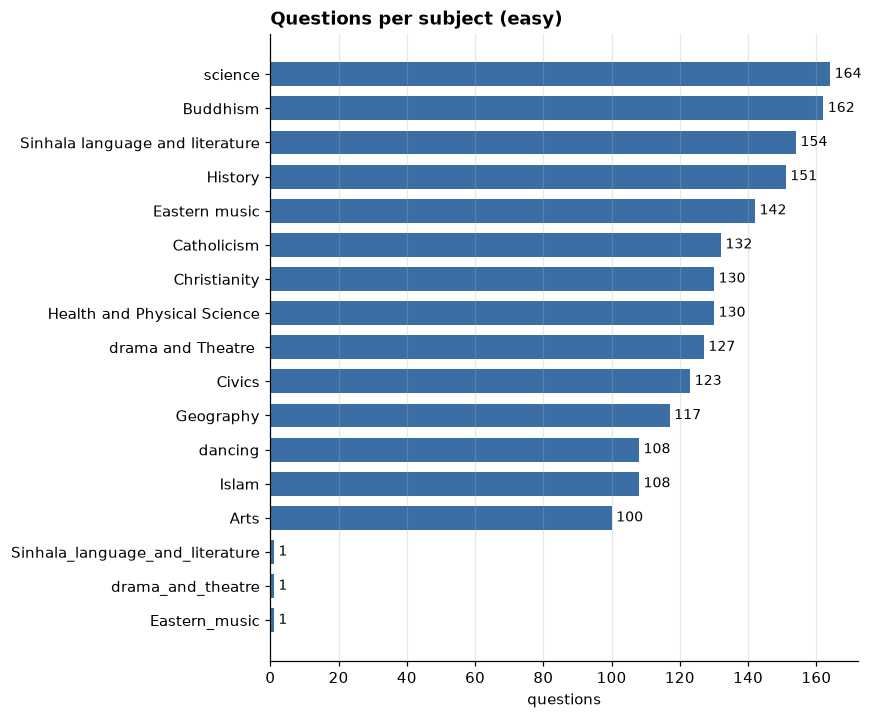

,questions,share_%
category,,
humanities,1162,62.8
social_science,370,20.0
stem,164,8.9
language,155,8.4


Total 1,851 vs 1,851 in the public HF Easy split (identical size).


In [33]:
barh(df["subject"].value_counts(), f"Questions per subject ({LEVEL})", "questions")

categories = df["category"].value_counts().to_frame("questions")
categories["share_%"] = (100 * categories["questions"] / len(df)).round(1)
display(categories)

if LEVEL == "easy":
    print(f"Total {len(df):,} vs {PUBLIC_EASY_SPLIT_SIZE:,} in the public HF Easy split "
          f"({'identical size' if len(df) == PUBLIC_EASY_SPLIT_SIZE else 'different size'}).")

In [34]:
if "meta_grade" in df:
    display(pd.crosstab(df["subject"], df["meta_grade"], margins=True, margins_name="total"))

if "meta_year" in df:
    display(df["meta_year"].value_counts().sort_index().to_frame("questions").T)

if "meta_type" in df:
    display(df["meta_type"].value_counts().head(15).to_frame("questions"))

if "meta_source" in df:
    df["source_domain"] = df["meta_source"].map(lambda url: urlparse(str(url)).netloc or "unknown")
    domains = df["source_domain"].value_counts()
    display(domains.to_frame("questions"))
    findings["source domains"] = ", ".join(domains.index)

meta_grade,6,7,8,total
subject,,,,
Arts,25,44,31,100
Buddhism,54,58,50,162
Catholicism,35,40,57,132
Christianity,29,31,70,130
Civics,38,37,48,123
Eastern music,46,66,30,142
Eastern_music,1,0,0,1
Geography,49,46,22,117
Health and Physical Science,35,43,52,130


meta_year,2018,2019,2020,2021,2022,2023
questions,111,846,317,3,246,328


,questions
meta_type,
P_NWP_3,366
P_CP,276
P_NWP_2,245
Z_Mathugama,206
P_SP_3,164
P_NWP_1,133
P_SP,85
P_SP_2,39
P_NCP_2,34


,questions
source_domain,
pastpapers.wiki,1721
www.e-thaksalawa.moe.gov.lk,93
unknown,28
C:,9


## 3. Answer options

- **Option count.** The shared task uses 4 options at every level — Hard questions had one wrong option dropped
  (SinhalaMMLU 2.0, official repo README). The official prompt template still says `1, 2, 3, 4, 5` for Hard, so a
  4-option Hard question needs the instruction built from the actual number of options.
- **Self-numbered options.** The template prepends `1. `, `2. ` … to each option. An option that already starts with
  a number gives `1. 1. …`. Review before touching: the number can be content (`1. වන උපතිස්ස` = "Upatissa I").
- **Label-combination options** (`ABCD`, `BADC`, `A හා C`) belong to matching / multi-statement questions — a known weak spot.
- **Duplicate options** make a question ambiguous; you cannot fix the test set, but expect noise there.

In [35]:
display(df["n_choices"].value_counts().sort_index().to_frame("questions"))
findings[f"questions with n_choices != {EXPECTED_N_CHOICES}"] = int((df["n_choices"] != EXPECTED_N_CHOICES).sum())

LABEL_COMBINATION = re.compile(r"^\s*[A-E](?:\s*(?:,|හා|සහ|and|-)?\s*[A-E])+\s*\.?\s*$")
STARTS_WITH_NUMBER_OR_LABEL = re.compile(r"^\s*(?:\(?\d+\s*[).]|\(?[A-E]\s*[).]|\([අආඇඈඉ]\))")
NUMERIC = re.compile(r"[\d\s.,/%:+\-]+")


def option_flags(choices: list[str]) -> dict[str, bool]:
    """Per-question flags describing the answer options."""
    keys = [normalise_key(c) for c in choices]
    return {
        "empty_option": any(not c.strip() for c in choices),
        "duplicate_options": len(set(keys)) < len(keys),
        "untrimmed_whitespace": any(c != c.strip() for c in choices),
        "self_numbered_option": any(STARTS_WITH_NUMBER_OR_LABEL.match(c) for c in choices),
        "label_combination_options": any(LABEL_COMBINATION.match(c) for c in choices),
        "all_or_none_of_above": any("ඉහත" in c for c in choices),
        "numeric_options": bool(choices) and all(NUMERIC.fullmatch(c.strip()) and re.search(r"\d", c) for c in choices),
    }


OPTION_FLAGS = list(option_flags(["x"]).keys())
df[OPTION_FLAGS] = pd.DataFrame(df["choices"].map(option_flags).tolist(), index=df.index)

option_summary = df[OPTION_FLAGS].sum().to_frame("questions")
option_summary["share_%"] = (100 * option_summary["questions"] / len(df)).round(1)
display(option_summary)
findings.update({f"options: {k}": int(v) for k, v in df[OPTION_FLAGS].sum().items()})

,questions
n_choices,
4,1851


,questions,share_%
empty_option,0,0.0
duplicate_options,7,0.4
untrimmed_whitespace,4,0.2
self_numbered_option,5,0.3
label_combination_options,13,0.7
all_or_none_of_above,11,0.6
numeric_options,17,0.9


In [36]:
for flag in ["duplicate_options", "self_numbered_option", "label_combination_options", "empty_option"]:
    print(f"\n--- {flag} ---")
    show_examples(df[flag], ["file", "q_no", "choices"])

print(f"\n--- n_choices != {EXPECTED_N_CHOICES} ---")
show_examples(df["n_choices"] != EXPECTED_N_CHOICES, ["file", "q_no", "n_choices", "choices"])


--- duplicate_options ---
7 matching question(s)


,file,q_no,choices
184,Buddhism_humanities_easy_f_162.json,85,"[අනේපිඬු සිටුතුමා හා සුජාතාවයි., අනේපිඬු සිටුතුමා හා විශාඛාවයි., බිම්බිසාර ර..."
597,Civics_social_science_easy_f_129.json,74,"[පාසල හා පුස්තකාලය, පාසල හා ප්‍රජා සංවර්ධන සමිති, පාසල හා පුස්තකාලය, අමද්‍යප..."
946,Eastern_music_humanities_easy_f_143.json,64,"[F, F, F, G]"



--- self_numbered_option ---
5 matching question(s)


,file,q_no,choices
311,Catholicism_humanities_easy_f_132.json,50,"[2. වන ජුවාම් පාවුළු ශුද්ධෝත්තම පියතුමා, V වන පියුස් ශුද්ධෝත්තම පියතුමා, සාන..."
372,Catholicism_humanities_easy_f_132.json,111,"[1. වන ෆ්‍රැන්සිස් ශුද්ධෝත්තම පියතුමා, XII පියුස් ශුද්ධෝත්තම පියතුමා, XIII බ..."
1339,History_social_science_easy_f_151.json,67,"[1. වන උපතිස්ස, බුද්ධදාස, 4. වන කාශ්‍යප, v මිහිඳු]"



--- label_combination_options ---
13 matching question(s)


,file,q_no,choices
1040,Geography_social_science_easy_f_117.json,15,"[ABCD, CDAB, BADC, DCBA]"
1041,Geography_social_science_easy_f_117.json,16,"[BACD, CBDA, ACDB, CDBA]"
1352,History_social_science_easy_f_151.json,80,"[ABCD, DEBA, BADC, CADB]"



--- empty_option ---
0 matching question(s)

--- n_choices != 4 ---
0 matching question(s)


## 4. Answer key distribution

How the correct answers spread over the option positions. The answer is read **back from the files** here (the loader
drops it) and resolved to a **1-based position**, so the official integer schema, a letter label (`A`…`E`) and an answer
given as the option text all work.

- **Position shares.** A skewed key means a constant guess beats chance — that is the floor your model must clear, and
  the reason a position-biased model can look better than it is.
- **Chi-square against a uniform key** separates a real skew from sampling noise.
- **Per subject**, because a skew confined to one subject says nothing about the set as a whole.
- **Unresolvable answers** (index out of range, text matching no option) are data errors your scorer must survive.
- **Length bias**: is the correct option simply the longest one? A classic shortcut that inflates dev scores.

**Rule note.** This runs on the files on disk — the public split, which ships *with* answers. The hidden Codabench
test set ships without them, so the section prints nothing there. Read the numbers as a **sanity baseline** (a model
scoring near the constant-guess floor has learnt nothing), not as a tie-break rule: steering low-confidence test
questions towards the most common position would be decision design on test answers. If you want a position prior,
measure it on the **dev set**.

In [37]:
LETTERS = "ABCDE"
CHI2_CRITICAL_5PCT = {1: 3.84, 2: 5.99, 3: 7.81, 4: 9.49, 5: 11.07, 6: 12.59}   # alpha = 0.05
MIN_SUBJECT_QUESTIONS = 30                        # below this, a per-subject share is noise


def load_answer_keys(path: Path) -> pd.DataFrame:
    """Read only `(file, q_no, answer)` from the question files, so gold answers stay out of `df`."""
    path = Path(path)
    files = [path] if path.is_file() else sorted(path.glob("*.json*"))
    return pd.DataFrame([
        {"file": file.name, "q_no": record.get("q_no"), "answer": record.get("answer")}
        for file in files for record in read_records(file)
    ])


def answer_position(answer: object, choices: list[str]) -> float:
    """Resolve a gold answer to a 1-based option position; NaN if it does not identify exactly one option."""
    if answer is None or isinstance(answer, bool) or not choices:
        return float("nan")
    text = str(answer).strip()
    if re.fullmatch(r"\d+", text):                                   # official schema: 1-based index
        position = int(text)
        return position if 1 <= position <= len(choices) else float("nan")
    if len(text) == 1 and text.upper() in LETTERS[:len(choices)]:    # letter label, A..E
        return LETTERS.index(text.upper()) + 1
    matches = [i for i, choice in enumerate(choices, start=1)        # answer given as the option text
               if normalise_key(choice) == normalise_key(text)]
    return matches[0] if len(matches) == 1 else float("nan")


KEY_COLUMNS = ["file", "q_no", "subject", "category", "n_choices", "choices"]
answer_key = df[KEY_COLUMNS + (["meta_grade"] if "meta_grade" in df else [])].merge(
    load_answer_keys(DATA_DIR), on=["file", "q_no"], how="left", validate="one_to_one")
answer_key["position"] = [answer_position(a, c) for a, c in zip(answer_key["answer"], answer_key["choices"])]

answered = answer_key["answer"].notna() & (answer_key["answer"].astype(str).str.strip() != "")
resolved = answer_key["position"].notna()
findings["answer key: resolvable answers"] = int(resolved.sum())
findings["answer key: answers resolving to no option"] = int((answered & ~resolved).sum())
print(f"{int(answered.sum()):,} of {len(answer_key):,} questions carry an answer; "
      f"{int(resolved.sum()):,} of those resolve to an option position.")

if (pd.to_numeric(answer_key["answer"], errors="coerce") == 0).any():
    print("WARNING: an answer of 0 appears, so this file may index options from 0. Every position below would then\n"
          "be off by one - check a few questions by hand before reading anything into the distribution.")
if not resolved.any():
    print(f"No resolvable answers under {DATA_DIR} - the rest of this section is empty, as expected for the\n"
          "hidden test set, which is released without answers.")
elif (answered & ~resolved).any():
    print("\nAnswers that do not identify an option (data errors - your scorer must not crash on these):")
    display(answer_key.loc[answered & ~resolved, ["file", "q_no", "n_choices", "answer"]])

1,851 of 1,851 questions carry an answer; 1,850 of those resolve to an option position.

Answers that do not identify an option (data errors - your scorer must not crash on these):


,file,q_no,n_choices,answer
1089,Geography_social_science_easy_f_117.json,64,4,24


,questions,share_%
option position,,
1,473,25.6
2,501,27.1
3,506,27.4
4,370,20.0


chi2 = 26.0 on 3 dof (5% critical value 7.81) - skewed, not sampling noise (p < 0.05)
Always answering 3 would score 27.4%, against 25.0% for a uniform key.


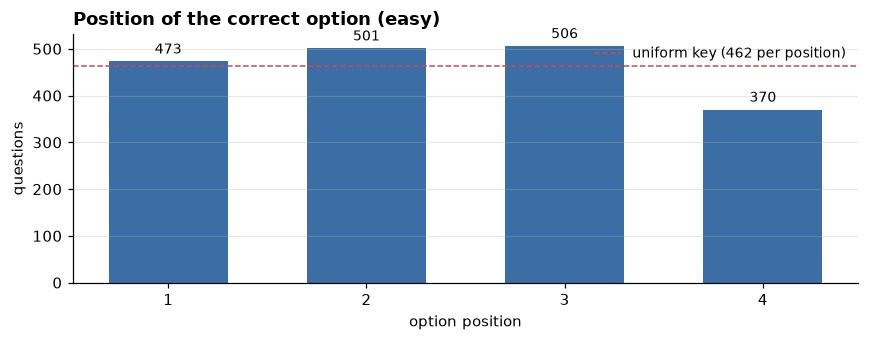

In [38]:
if resolved.any():
    positions = answer_key.loc[resolved, "position"].astype(int)
    position_counts = positions.value_counts().sort_index()
    n_resolved = int(position_counts.sum())

    distribution = position_counts.to_frame("questions")
    distribution["share_%"] = (100 * distribution["questions"] / n_resolved).round(1)
    distribution.index.name = "option position"
    display(distribution)

    uniform = n_resolved / len(position_counts)
    chi2 = float(((position_counts - uniform) ** 2 / uniform).sum())
    dof = len(position_counts) - 1
    critical = CHI2_CRITICAL_5PCT.get(dof)
    verdict = ("skewed, not sampling noise (p < 0.05)" if critical and chi2 > critical else
               "consistent with a uniform key" if critical else "no critical value tabulated for this dof")
    best_position, best_share = int(distribution["share_%"].idxmax()), float(distribution["share_%"].max())
    print(f"chi2 = {chi2:.1f} on {dof} dof (5% critical value {critical}) - {verdict}")
    print(f"Always answering {best_position} would score {best_share:.1f}%, against {100 / len(position_counts):.1f}% "
          "for a uniform key.")

    findings["answer key: chi2 vs uniform"] = round(chi2, 1)
    findings["answer key: best constant guess"] = f"option {best_position} ({best_share:.1f}%)"
    findings.update({f"answer key: position {p} %": s for p, s in distribution["share_%"].items()})

    fig, ax = plt.subplots(figsize=(8, 3.2))
    bars = ax.bar(position_counts.index.astype(str), position_counts.values, color=BAR_COLOR, width=0.6)
    ax.bar_label(bars, fmt="{:,.0f}", padding=3, fontsize=9)
    ax.axhline(uniform, color="#C44E52", linestyle="--", linewidth=1,
               label=f"uniform key ({uniform:,.0f} per position)")
    ax.set_title(f"Position of the correct option ({LEVEL})", loc="left")
    ax.set_xlabel("option position")
    ax.set_ylabel("questions")
    ax.legend(frameon=False, fontsize=9)
    ax.grid(axis="x", visible=False)
    plt.tight_layout()
    plt.show()

In [39]:
if resolved.any():
    by_subject = pd.crosstab(answer_key.loc[resolved, "subject"], positions, normalize="index").mul(100).round(1)
    by_subject.columns = [f"pos {position} %" for position in by_subject.columns]
    by_subject.insert(0, "questions", answer_key.loc[resolved].groupby("subject").size())
    by_subject["best constant guess %"] = by_subject.filter(like="pos ").max(axis=1)
    display(by_subject.sort_values("best constant guess %", ascending=False))

    # Tiny subjects (often a stray spelling of a bigger one - see the per-file checks in §1) are ignored here.
    large = by_subject[by_subject["questions"] >= MIN_SUBJECT_QUESTIONS]
    if not large.empty:
        worst = large["best constant guess %"].idxmax()
        print(f"Strongest skew among subjects with >= {MIN_SUBJECT_QUESTIONS} questions: {worst} "
              f"({large.loc[worst, 'best constant guess %']:.1f}% on one position).")
        findings["answer key: largest per-subject position share %"] = float(large["best constant guess %"].max())

    if "meta_grade" in answer_key:
        display(pd.crosstab(answer_key.loc[resolved, "meta_grade"], positions,
                            normalize="index").mul(100).round(1).rename(columns=lambda p: f"pos {p} %"))

,questions,pos 1 %,pos 2 %,pos 3 %,pos 4 %,best constant guess %
subject,,,,,,
Eastern_music,1,0.0,0.0,100.0,0.0,100.0
drama_and_theatre,1,100.0,0.0,0.0,0.0,100.0
Sinhala_language_and_literature,1,0.0,100.0,0.0,0.0,100.0
Civics,123,23.6,21.1,34.1,21.1,34.1
Eastern music,142,19.7,33.1,28.9,18.3,33.1
Geography,116,25.0,32.8,26.7,15.5,32.8
Christianity,130,20.8,32.3,26.9,20.0,32.3
drama and Theatre,127,26.0,21.3,32.3,20.5,32.3
Islam,108,31.5,26.9,23.1,18.5,31.5


Strongest skew among subjects with >= 30 questions: Civics (34.1% on one position).


position,pos 1 %,pos 2 %,pos 3 %,pos 4 %
meta_grade,,,,
6,24.5,27.4,28.1,20.0
7,25.9,26.5,28.7,18.9
8,26.3,27.4,25.3,21.0


In [40]:
if resolved.any():
    def length_flags(choices: list[str], position: int) -> dict[str, bool]:
        """Is the correct option the one and only longest / shortest option?"""
        lengths = [len(choice.strip()) for choice in choices]
        correct = lengths[position - 1]
        return {"correct option is the longest": correct == max(lengths) and lengths.count(correct) == 1,
                "correct option is the shortest": correct == min(lengths) and lengths.count(correct) == 1}

    length_bias = pd.DataFrame([length_flags(c, p) for c, p in zip(answer_key.loc[resolved, "choices"], positions)])
    shares = (100 * length_bias.mean()).round(1).to_frame("% of questions")
    shares["chance_%"] = round(100 * (1 / answer_key.loc[resolved, "n_choices"]).mean(), 1)
    display(shares)
    findings.update({f"answer key: {flag.removeprefix('correct option is the ')}-option guess %": value
                     for flag, value in shares["% of questions"].items()})

,% of questions,chance_%
correct option is the longest,23.8,25.0
correct option is the shortest,16.3,25.0


## 5. Length and layout

Lengths are in characters and whitespace-separated words; §9 converts them to tokens. Layout artefacts from PDF
extraction — runs of spaces, line breaks inside a question — cost tokens and look unlike your training text. If they
are common, normalise whitespace **identically** in training data and at inference.

In [41]:
df["question_chars"] = df["question"].str.len()
df["question_words"] = df["question"].str.split().str.len()
df["option_chars_mean"] = df["choices"].map(lambda cs: sum(map(len, cs)) / max(len(cs), 1))

display(df[["question_chars", "question_words", "option_chars_mean"]]
        .describe(percentiles=[0.5, 0.9, 0.99]).round(1))

paper_q, paper_a = PAPER_MEAN_CHARS[LEVEL]
print(f"Mean question length: {df['question_chars'].mean():.1f} chars (paper, all {LEVEL}: {paper_q})")
print(f"Mean option length:   {df['option_chars_mean'].mean():.1f} chars (paper answer length, all {LEVEL}: {paper_a})")
findings["question_chars p99"] = round(df["question_chars"].quantile(0.99), 1)
findings["question_chars max"] = int(df["question_chars"].max())

,question_chars,question_words,option_chars_mean
count,1851.0,1851.0,1851.0
mean,72.4,11.3,16.4
std,69.3,10.6,10.8
min,9.0,2.0,1.0
50%,57.0,9.0,14.0
90%,113.0,17.0,30.0
99%,435.5,67.0,52.8
max,722.0,109.0,78.0


Mean question length: 72.4 chars (paper, all easy: 59.08)
Mean option length:   16.4 chars (paper answer length, all easy: 16.77)


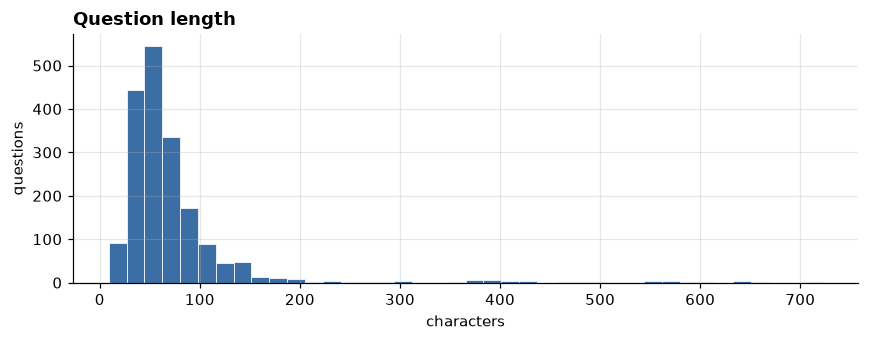

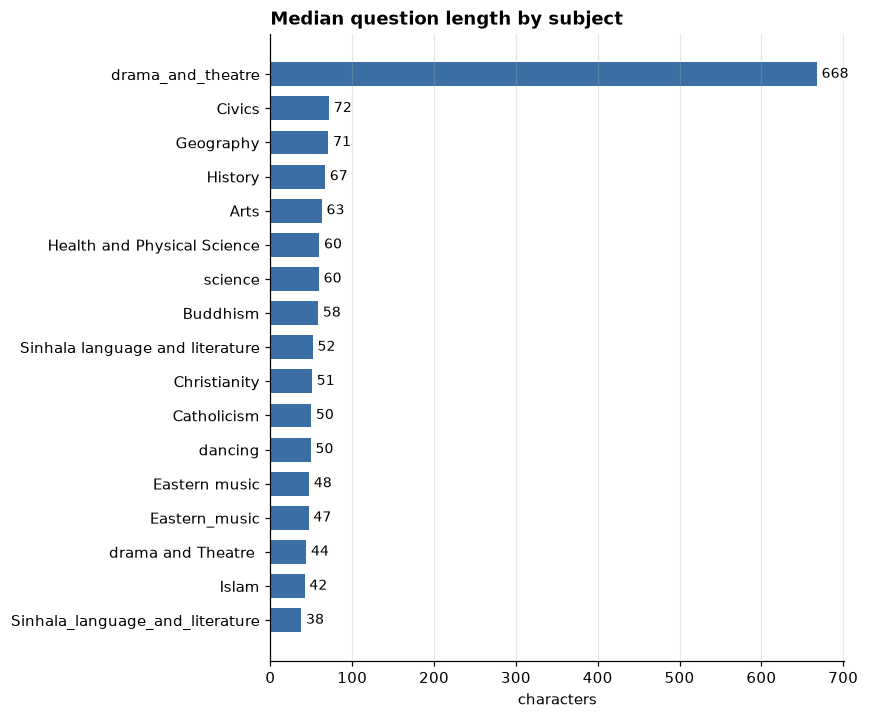

In [42]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(df["question_chars"], bins=40, color=BAR_COLOR, edgecolor="white", linewidth=0.5)
ax.set_title("Question length", loc="left")
ax.set_xlabel("characters")
ax.set_ylabel("questions")
plt.tight_layout()
plt.show()

barh(df.groupby("subject")["question_chars"].median(), "Median question length by subject", "characters")

In [43]:
layout = pd.Series({
    "line break(s) inside the question": int(df["question"].str.contains("\n").sum()),
    "run of 3+ spaces inside the question": int(df["question"].str.contains(" {3,}").sum()),
    "leading/trailing whitespace": int((df["question"] != df["question"].str.strip()).sum()),
    "question ends with ',' (sentence to complete)": int(df["question"].str.strip().str.endswith(",").sum()),
    "question ends with '?'": int(df["question"].str.strip().str.endswith("?").sum()),
}, name="questions")
display(layout.to_frame())
findings.update({f"layout: {k}": v for k, v in layout.items()})

print("Longest questions:")
display(df.nlargest(5, "question_chars")[["file", "q_no", "question_chars", "question"]])

,questions
line break(s) inside the question,452
run of 3+ spaces inside the question,19
leading/trailing whitespace,352
"question ends with ',' (sentence to complete)",1148
question ends with '?',264


Longest questions:


,file,q_no,question_chars,question
1040,Geography_social_science_easy_f_117.json,15,722,I උෂ්ණත්වය ...
755,drama_and_theatre_humanities_easy_f_128.json,1,668,"A,B,C,D කොටස් ඇසුරෙන් පහත ප්‍රශ්නයට පිළිතුරු සපයන්න\n\nA රජ්ජුරුවන්ගෙන් පණිව..."
758,drama_and_theatre_humanities_easy_f_128.json,4,666,"A,B,C,D කොටස් ඇසුරෙන් පහත ප්‍රශ්නයට පිළිතුරු සපයන්න\n\nA රජ්ජුරුවන්ගෙන් පණිව..."
757,drama_and_theatre_humanities_easy_f_128.json,3,646,"A,B,C,D කොටස් ඇසුරෙන් පහත ප්‍රශ්නයට පිළිතුරු සපයන්න\n\nA රජ්ජුරුවන්ගෙන් පණිව..."
759,drama_and_theatre_humanities_easy_f_128.json,5,642,"A,B,C,D කොටස් ඇසුරෙන් පහත ප්‍රශ්නයට පිළිතුරු සපයන්න\n\nA රජ්ජුරුවන්ගෙන් පණිව..."


## 6. Script and Unicode hygiene

What to look for:

- **Non-NFC text** and **orphan signs** mean the inference pipeline needs normalisation (or the text is broken).
- **Stray ZWJ / any ZWNJ / ZWSP / NBSP / BOM.** Your CPT pipeline strips stray ZWJ, ZWSP, BOM and soft hyphens;
  check whether it also handles ZWNJ. Whatever you strip in training you must strip at inference too, or the model
  sees token sequences it never trained on.
- **Conjunct conventions** (repaya / rakaransaya / yansaya with or without ZWJ). Pick the convention on the **dev set**;
  use these counts only to confirm dev and test agree.
- **Low Sinhala ratio** — English or symbol-heavy questions, or unconverted legacy-font text (looks like `b;sydih`).

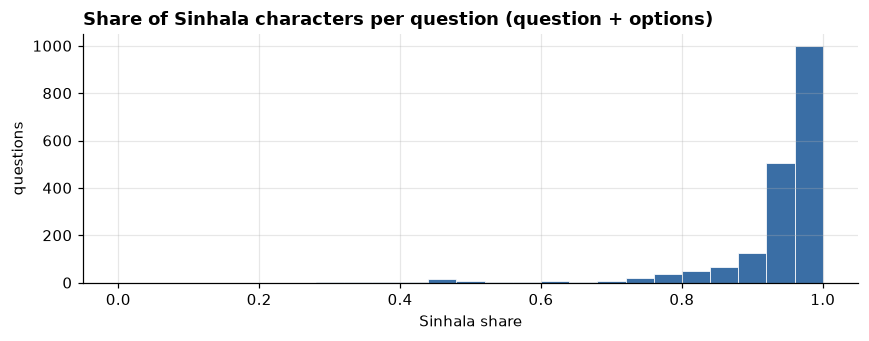

Lowest Sinhala share:


,file,q_no,sinhala_ratio,question
1111,Geography_social_science_easy_f_117.json,86,0.318182,ශ්‍රී ලංකාවේ උතුරු පළාත දිස්ත්‍රික්ක ..........................................
1118,Geography_social_science_easy_f_117.json,93,0.355263,පෘථිවි ගෝලයේ මතුපිට වර්ග ප්‍රමාණය වර්ග කිලෝමීටර් මිලියන .......................
1113,Geography_social_science_easy_f_117.json,88,0.390071,ශ්‍රී ලංකාවේ තැනිතලා ප්‍රදේශවල ................................................
1120,Geography_social_science_easy_f_117.json,95,0.390411,පෘථිවි පෘෂ්ඨයේ 71% ක් .........................................................
1131,Geography_social_science_easy_f_117.json,106,0.414966,ශ්‍රී ලංකාව ...................................................................


In [44]:
df["sinhala_ratio"] = df["all_text"].map(sinhala_ratio)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(df["sinhala_ratio"], bins=25, range=(0, 1), color=BAR_COLOR, edgecolor="white", linewidth=0.5)
ax.set_title("Share of Sinhala characters per question (question + options)", loc="left")
ax.set_xlabel("Sinhala share")
ax.set_ylabel("questions")
plt.tight_layout()
plt.show()

findings["questions with < 50% Sinhala characters"] = int((df["sinhala_ratio"] < 0.5).sum())
print("Lowest Sinhala share:")
display(df.nsmallest(5, "sinhala_ratio")[["file", "q_no", "sinhala_ratio", "question"]])

In [45]:
other_chars = Counter(
    ch for text in df["all_text"] for ch in text
    if not SINHALA_CHAR.match(ch) and not ch.isspace()
)
display(pd.DataFrame(
    [(repr(ch), f"U+{ord(ch):04X}", unicodedata.name(ch, "?"), n) for ch, n in other_chars.most_common(30)],
    columns=["char", "code point", "name", "count"],
))

,char,code point,name,count
0,'.',U+002E,FULL STOP,7716
1,'\u200d',U+200D,ZERO WIDTH JOINER,2731
2,"','",U+002C,COMMA,2361
3,"'""'",U+0022,QUOTATION MARK,376
4,'?',U+003F,QUESTION MARK,274
5,'-',U+002D,HYPHEN-MINUS,254
6,'0',U+0030,DIGIT ZERO,219
7,'1',U+0031,DIGIT ONE,194
8,')',U+0029,RIGHT PARENTHESIS,188
9,'A',U+0041,LATIN CAPITAL LETTER A,166


In [46]:
not_nfc = df["all_text"] != df["all_text"].map(lambda t: unicodedata.normalize("NFC", t))

hygiene = {"not NFC-normalised": {"questions": int(not_nfc.sum()), "occurrences": None}}
hygiene["orphan vowel sign / al-lakuna"] = pattern_counts(df["all_text"], ORPHAN_SIGN)
hygiene["stray ZWJ (not after al-lakuna)"] = pattern_counts(df["all_text"], STRAY_ZWJ)
for name, ch in INVISIBLE_CHARS.items():
    hygiene[name] = pattern_counts(df["all_text"], re.compile(re.escape(ch)))

hygiene = pd.DataFrame(hygiene).T
display(hygiene)
findings.update({f"unicode: {k}": int(v) for k, v in hygiene["questions"].items()})

print("Examples - orphan signs:")
show_examples(df["all_text"].str.contains(ORPHAN_SIGN), ["file", "q_no", "question"])

,questions,occurrences
not NFC-normalised,0.0,NaN
orphan vowel sign / al-lakuna,4.0,4.0
stray ZWJ (not after al-lakuna),3.0,3.0
ZWJ (U+200D),1191.0,2731.0
ZWNJ (U+200C),29.0,75.0
ZWSP (U+200B),0.0,0.0
NBSP (U+00A0),0.0,0.0
BOM (U+FEFF),0.0,0.0
soft hyphen (U+00AD),0.0,0.0


Examples - orphan signs:
4 matching question(s)


,file,q_no,question
743,dancing_humanities_easy_f_108.json,97,"ඊෂ්වර කුණ්ඩතාලය සිංදු වන්නමෙි අවසාන කව් පදය වන්නේ,"
1110,Geography_social_science_easy_f_117.json,85,වයඹ පළාතට කුරුණෑගල හා ................. දිසිීකික්කය ද අයත්‌ ය.
1231,Health_and_Physical_Science_social_science_easy_f_130.json,89,"ස්ත්‍රී හා පුරුෂ පද්ධති පිළිබඳ M, N, O, P අක්ෂර වලින් පහත දැක්වේ.\nM-පුරුෂ ප..."


In [47]:
conventions = pd.DataFrame({name: pattern_counts(df["all_text"], p) for name, p in CONVENTIONS.items()}).T
display(conventions)

,questions,occurrences
repaya with ZWJ (ර්‍ක),0,0
repaya without ZWJ (ර්ක),653,969
rakaransaya with ZWJ (ක්‍ර),969,1856
rakaransaya without ZWJ (ක්ර),38,46
yansaya with ZWJ (ක්‍ය),532,836
yansaya without ZWJ (ක්ය),140,191


## 7. Question types

Keyword heuristics — good enough for rates, not for labelling. Review the examples before trusting a bucket.
The SinhalaMMLU paper found every model scored worse on **negation** and **sub-option** questions. **Figure/table
references** usually point to an image the model never sees, so expect near-chance accuracy there.
Use the rates to check that your **dev set has a similar mix** — if it does, dev-based decisions should transfer.

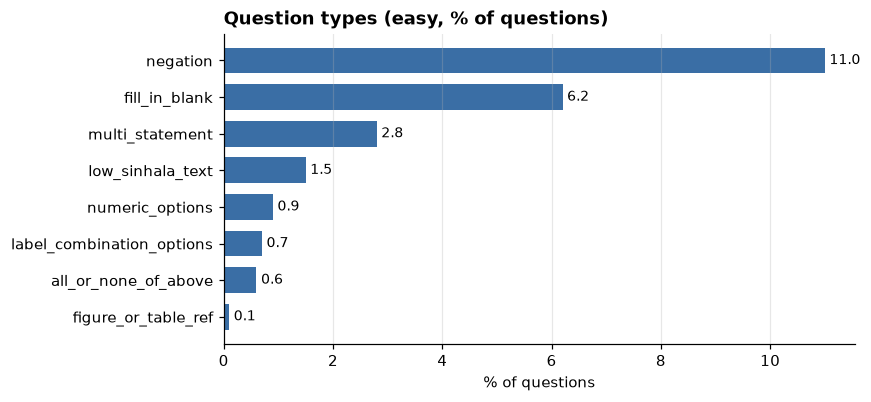

,negation,multi_statement,label_combination_options,fill_in_blank,figure_or_table_ref,all_or_none_of_above,numeric_options,low_sinhala_text
subject,,,,,,,,
Arts,7.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
Buddhism,6.8,0.0,0.0,1.9,0.0,0.0,0.0,0.0
Catholicism,3.8,0.0,0.0,4.5,0.0,0.0,0.0,0.0
Christianity,6.9,0.0,0.0,0.0,0.0,0.0,0.8,0.0
Civics,16.3,0.0,0.0,0.0,0.0,0.0,1.6,0.0
Eastern music,6.3,0.7,0.0,9.2,0.0,0.0,0.0,0.0
Eastern_music,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Geography,8.5,1.7,1.7,40.2,0.9,0.0,2.6,23.1
Health and Physical Science,11.5,0.0,0.0,0.8,0.0,2.3,0.8,0.0


In [48]:
NEGATION = re.compile(r"සාවද්ය|අසත්ය|වැරදි|නොගැළපෙ|නොගැලපෙ|නොවන|නොවේ|නොවූ|නොකළ|නොකරන")
FILL_IN_BLANK = re.compile(r"_{2,}|\.{4,}|…")
FIGURE_OR_TABLE = re.compile(r"පහත (?:රූප|වගු|සටහන|සිතියම|ප්රස්තාර)|රූප සටහන|රූපයේ දැක්වෙ|වගුවේ|සිතියමේ|ප්රස්තාරයේ")
STATEMENT_LABEL = re.compile(r"(?<![A-Za-z])(?:[A-E]|I{1,3}|IV|V)(?![A-Za-z])")

question_text = df["question"].map(strip_zero_width)
df["negation"] = question_text.str.contains(NEGATION)
df["fill_in_blank"] = question_text.str.contains(FILL_IN_BLANK)
df["figure_or_table_ref"] = question_text.str.contains(FIGURE_OR_TABLE)
df["multi_statement"] = question_text.map(lambda q: len(set(STATEMENT_LABEL.findall(q))) >= 2)
df["low_sinhala_text"] = df["sinhala_ratio"] < 0.5

BUCKETS = ["negation", "multi_statement", "label_combination_options", "fill_in_blank",
           "figure_or_table_ref", "all_or_none_of_above", "numeric_options", "low_sinhala_text"]

bucket_share = (100 * df[BUCKETS].mean()).round(1)
barh(bucket_share, f"Question types ({LEVEL}, % of questions)", "% of questions", fmt="{:.1f}")
findings.update({f"type %: {k}": v for k, v in bucket_share.items()})

display((100 * df.groupby("subject")[BUCKETS].mean()).round(1))

In [49]:
for bucket in ["negation", "multi_statement", "figure_or_table_ref", "fill_in_blank"]:
    print(f"\n--- {bucket} ---")
    show_examples(df[bucket], ["file", "q_no", "question"])


--- negation ---
203 matching question(s)


,file,q_no,question
5,Arts_humanities_easy_f_97.json,6,දේශීය සැරසිලි මූලිකාංග වර්ගීකරණයට අයත් නොවන්නේ මෙයින් කුමන කාණ්ඩය ද?
6,Arts_humanities_easy_f_97.json,7,"ජේසු උපත සමරන නත්තල් උත්සවයේ දී කිතුනුවන් විසින් කරනු ලබන සැරසිල්ලක් නොවන්නේ,"
36,Arts_humanities_easy_f_97.json,37,"ශ්‍රී ලංකාවේ ප්‍රාග් ඓතිහාසික ගුහා චිත්‍ර දැකගත හැකි ස්ථානයක් නොවන්නේ,"



--- multi_statement ---
52 matching question(s)


,file,q_no,question
755,drama_and_theatre_humanities_easy_f_128.json,1,"A,B,C,D කොටස් ඇසුරෙන් පහත ප්‍රශ්නයට පිළිතුරු සපයන්න\n\nA රජ්ජුරුවන්ගෙන් පණිව..."
756,drama_and_theatre_humanities_easy_f_128.json,2,"A,B,C,D කොටස් ඇසුරෙන් පහත ප්‍රශ්නයට පිළිතුරු සපයන්න\n\nA රජ්ජුරුවන්ගෙන් පණිව..."
757,drama_and_theatre_humanities_easy_f_128.json,3,"A,B,C,D කොටස් ඇසුරෙන් පහත ප්‍රශ්නයට පිළිතුරු සපයන්න\n\nA රජ්ජුරුවන්ගෙන් පණිව..."



--- figure_or_table_ref ---
2 matching question(s)


,file,q_no,question
1056,Geography_social_science_easy_f_117.json,31,"සිතියමේ දැක්වෙන ලක්ෂණ හදුනා ගැනීමට උපකාරී වන ප්‍රධාන සාධකයක් ලෙස සැලකේනේ ,"
1661,science_stem_easy_f_163.json,130,අහස නිරීක්ෂණයේ යෙදුණු සිසුවෙක් තම ක්ෂේත්‍ර පොතේ පහත සටහන තබන ලදී.\nA. තරුවක ...



--- fill_in_blank ---
114 matching question(s)


,file,q_no,question
33,Arts_humanities_easy_f_97.json,34,කැලණි විහාරයේ වර්තමාන ස්ථූපය ..................................................
109,Buddhism_humanities_easy_f_162.json,10,ඉතිපි සෝ භගවා අරහං ...... විජ්ජාචරණ යනාදී ගාථා පාඨයෙහි හිස්තැනට නියමිත බුදුග...
110,Buddhism_humanities_easy_f_162.json,11,"යස්ස මුලේ නිසින්නෝ............ මෙම ගාථාව සජ්ඣායනා කරමින් වන්දනා කරන්නේ,"


## 8. Duplicates and overlap

Duplicates are matched on a normalised key (NFC, zero-width characters removed, whitespace collapsed). Short generic
stems can repeat legitimately with different options, so both "question only" and "question + options" are reported.

Set `COMPARE_PATH` to compare against another set:
- **the Codabench test file** — a high overlap means this folder *is* the test set with answers attached;
- **your dev set** — overlap means dev scores are inflated;
- **your training corpus export** (as JSON/JSONL with a `question` field) — overlap means contamination.

In [50]:
df["question_key"] = df["question"].map(normalise_key)
df["question_options_key"] = df["question_key"] + " || " + df["choices"].map(
    lambda cs: " | ".join(sorted(normalise_key(c) for c in cs)))

dup_question = df.duplicated("question_key", keep=False)
dup_full = df.duplicated("question_options_key", keep=False)
cross_subject = df[dup_question].groupby("question_key")["subject"].nunique().gt(1).sum()

findings["duplicate questions (question only)"] = int(dup_question.sum())
findings["duplicate questions (question + options)"] = int(dup_full.sum())
print(f"Questions sharing their text with another question: {int(dup_question.sum())}")
print(f"Questions sharing text AND options:                 {int(dup_full.sum())}")
print(f"Duplicate texts spread over more than one subject:  {int(cross_subject)}")
display(df[dup_question].sort_values("question_key")[["file", "q_no", "question", "choices"]].head(10))

Questions sharing their text with another question: 18
Questions sharing text AND options:                 0
Duplicate texts spread over more than one subject:  0


,file,q_no,question,choices
1843,Sinhala_language_and_literature_language_easy_f_155.json,148,අක්ෂර වින්‍යාසය නිවැරදි පදය තෝරන්න.,"[අධිකරන, අදිකරණ, අදිකරන, අධිකරණ]"
1844,Sinhala_language_and_literature_language_easy_f_155.json,149,අක්ෂර වින්‍යාසය නිවැරදි පදය තෝරන්න.,"[බික්ෂුණි, භික්ෂුනී, භික්ෂුණී, භික්සුනී]"
1698,Sinhala_language_and_literature_language_easy_f_155.json,3,අනුක්ත නාම පද පමණක් ඇතුළත් පිළිතුර තෝරන්න.,"[කුරුල්ලෝ, වැඩිහිටියන්, කවීන්., ඔවුන්, සිංහයන්, රෝගීන්., ළමයි, ගුරුවරු, උගතු..."
1717,Sinhala_language_and_literature_language_easy_f_155.json,22,අනුක්ත නාම පද පමණක් ඇතුළත් පිළිතුර තෝරන්න.,"[මම, අප, ගුරුවරු, ඔවුන්, තෝ, ළමයින්, දැරියක, ගොවියෙකු, තොප, මා, හාවා, මිනිස්සු]"
1795,Sinhala_language_and_literature_language_easy_f_155.json,100,"තද්ධිත නාමයක් වන්නේ ,","[හැකියා, දේශීය, දුවන්නී, කම්කරු]"
1835,Sinhala_language_and_literature_language_easy_f_155.json,140,"තද්ධිත නාමයක් වන්නේ ,","[දේශීය, රවුම, කාලය, රට]"
1735,Sinhala_language_and_literature_language_easy_f_155.json,40,නිවැරදි අක්ෂර වින්‍යාසයෙන් යුතු වචනය තෝරන්න .,"[ප්‍රථිඵලය, මහළු මිනිසා, පරීක්ෂණය, විෂේස]"
1736,Sinhala_language_and_literature_language_easy_f_155.json,41,නිවැරදි අක්ෂර වින්‍යාසයෙන් යුතු වචනය තෝරන්න .,"[දර්ශනය, දක්සින, පෝශනය, පරිඝනකය]"
1719,Sinhala_language_and_literature_language_easy_f_155.json,24,නිවැරදි අක්‍ෂර වින්‍යාසයෙන් යුතු වචනය තෝරන්න.,"[ස්ථාවර, ප්‍රථිපත්තිය, පුෂ්ඵය, කූඨය]"
1720,Sinhala_language_and_literature_language_easy_f_155.json,25,නිවැරදි අක්‍ෂර වින්‍යාසයෙන් යුතු වචනය තෝරන්න.,"[පරික්සනය, අවබෝදය, දක්ෂිණ, මහළු]"


In [51]:
if COMPARE_PATH is None:
    print("COMPARE_PATH is not set - overlap check skipped.")
else:
    other = load_questions(Path(COMPARE_PATH))
    other_keys = set(other["question"].fillna("").astype(str).map(normalise_key))
    overlap = df["question_key"].isin(other_keys)
    findings["overlap with COMPARE_PATH"] = int(overlap.sum())
    print(f"{int(overlap.sum()):,} of {len(df):,} questions ({overlap.mean():.1%}) also appear in {COMPARE_PATH}")
    display(overlap.groupby(df["subject"]).mean().mul(100).round(1).to_frame("overlap_%"))

COMPARE_PATH is not set - overlap check skipped.


## 9. Token lengths (optional)

Builds the **official zero-shot Sinhala prompt** (subject intro on, as in the paper's `util_prompt.py`) and measures
it with each tokenizer in `TOKENIZERS`. The chat template adds a few dozen more tokens on top.

- `prompt_tokens p99 / max` → your `max_seq_len` and batch size for inference.
- `tokens_per_word` (fertility) → lower is better; it is the main reason the plan prefers 262k-vocabulary tokenizers for Sinhala.
- `digits_single_token` → probability scoring over option digits assumes each of `1`–`4` is one token.

This measures a template you already chose; it is not a licence to tune the template on test questions.

In [52]:
# Official template text (naist-nlp/SinhalaMMLU src/util_prompt.py). "\u200D" is the ZWJ inside ප්\u200Dර.
INTRO = "මෙය {subject} විෂයයට අදාළ බහුවරණ ප්\u200Dරශ්නයකි.\n"
INSTRUCTION = {
    "easy": "පහත ප්\u200Dරශ්නයට 1, 2, 3, 4 යන පිළිතුරුවලින් නිවැරදි හෝ ඉතාමත් ගැළපෙන පිළිතුර තෝරන්න.\n\n",
    "medium": "පහත ප්\u200Dරශ්නයට 1, 2, 3, 4  යන පිළිතුරුවලින් නිවැරදි හෝ ඉතාමත් ගැළපෙන පිළිතුර තෝරාගන්න.\n\n",
    "hard": "පහත ප්\u200Dරශ්නයට 1, 2, 3, 4, 5 යන පිළිතුරුවලින් නිවැරදි හෝ ඉතාමත් ගැළපෙන පිළිතුර තෝරාගන්න.\n\n",
}


def build_prompt(row: pd.Series) -> str:
    """Official SinhalaMMLU zero-shot prompt, without the model's chat template."""
    subject = row.get("meta_subject_original") or row["subject"]
    options = "\n".join(f"{i}. {c.strip()}" for i, c in enumerate(row["choices"], start=1))
    return (INTRO.format(subject=subject) + INSTRUCTION[LEVEL]
            + f"ප්\u200Dරශ්නය: {row['question']}\n{options}\nපිළිතුර:")


def token_stats(tokenizer, prompts: pd.Series, questions: pd.Series) -> dict[str, float]:
    """Prompt-length percentiles and Sinhala fertility for one tokenizer."""
    def n_tokens(text: str) -> int:
        return len(tokenizer.encode(text, add_special_tokens=False))

    prompt_tokens = prompts.map(n_tokens)
    question_tokens = questions.map(n_tokens)
    return {
        "prompt_tokens mean": prompt_tokens.mean(),
        "prompt_tokens p99": prompt_tokens.quantile(0.99),
        "prompt_tokens max": prompt_tokens.max(),
        "tokens_per_word": question_tokens.sum() / max(questions.str.split().str.len().sum(), 1),
        "chars_per_token": questions.str.len().sum() / max(question_tokens.sum(), 1),
        "digits_single_token": all(n_tokens(d) == 1 for d in "1234"),
    }


prompts = df.apply(build_prompt, axis=1)
print(prompts.iloc[0])

මෙය චිත්‍ර විෂයයට අදාළ බහුවරණ ප්‍රශ්නයකි.
පහත ප්‍රශ්නයට 1, 2, 3, 4 යන පිළිතුරුවලින් නිවැරදි හෝ ඉතාමත් ගැළපෙන පිළිතුර තෝරන්න.

ප්‍රශ්නය: වෙසක් උත්සවයේදී බෞද්ධයින් අනුගමනය කරන පූජා විධි දෙක නම්,
1. ආමිස පූජා සහ ප්‍රතිපත්ති පූජා
2. මල් පූජා හා පහන් පූජා
3. ද්‍රව්‍ය පූජා සහ භාණ්ඩ පූජා
4. ආහාර පූජා හා වස්ත්‍ර පූජා
පිළිතුර:


In [53]:
try:
    from transformers import AutoTokenizer
except ImportError:
    AutoTokenizer = None
    print("transformers is not installed - token-length section skipped (pip install transformers).")

token_rows = {}
for label, model_id in (TOKENIZERS if AutoTokenizer else {}).items():
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_id)
    except Exception as err:  # gated repo, no network, unknown model id, ...
        print(f"Skipping {label}: {type(err).__name__}: {str(err)[:150]}")
        continue
    token_rows[label] = token_stats(tokenizer, prompts, df["question"])

if token_rows:
    token_table = pd.DataFrame.from_dict(token_rows, orient="index")
    display(token_table.round(2))
    for label, row in token_table.iterrows():
        findings[f"{label}: prompt tokens max"] = int(row["prompt_tokens max"])

,prompt_tokens mean,prompt_tokens p99,prompt_tokens max,tokens_per_word,chars_per_token,digits_single_token
Qwen3.5-4B-Base,245.57,453.0,663,4.70,1.36,True
Gemma-3-4B-it,166.10,315.5,469,2.98,2.14,True


## 10. Summary

The numbers below are aggregates only (no question text), so the CSVs written to `reports/eda/` are safe to keep.

In [54]:
summary = pd.Series(findings, name="value").astype(str).to_frame()
display(summary)

subject_summary = (
    df.groupby("subject")
    .agg(questions=("q_no", "size"), category=("category", "first"),
         question_chars_median=("question_chars", "median"), sinhala_ratio_mean=("sinhala_ratio", "mean"))
    .join((100 * df.groupby("subject")[BUCKETS].mean()).add_suffix("_%"))
    .round(2)
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)
summary.to_csv(REPORT_DIR / f"test_{LEVEL}_findings.csv", encoding="utf-8")
subject_summary.to_csv(REPORT_DIR / f"test_{LEVEL}_by_subject.csv", encoding="utf-8")
print(f"Saved to {REPORT_DIR}")

,value
questions,1851
files,14
subjects,17
empty question,0
choices missing or empty,0
missing subject,0
missing category,0
"duplicate (subject, q_no) keys",0
metadata.difficulty != 'easy',0
questions carrying a gold answer,1851


Saved to d:\Competetions\Sinhala MMLU\reports\eda


## From findings to actions

| If you see… | Do this |
|---|---|
| Files carry gold answers | Not the Codabench file. Set `COMPARE_PATH` to the Codabench test file; if overlap is high, never use these answers (not even for validation) and ask the organisers in writing. |
| `n_choices` ≠ 4, empty or duplicate options | Make the scorer read the option count from each record; never hard-code 4 or 5. |
| Self-numbered options | Leave the content alone; just confirm the prompt still reads sensibly (`1. 1. …`). |
| Answer key skewed towards one position | Treat that share as the floor, not a strategy: if your model's accuracy is near it, check the option-position bias of its predictions before celebrating. |
| Non-NFC text, stray ZWJ, ZWNJ, NBSP, runs of spaces | Put **one** normaliser in `src/` and call it from both the CPT/SFT data pipeline and the inference script. |
| Conjunct convention differs from your corpus | Re-check on the dev set, then align the corpus convention (`repaya_zwj`). |
| Source domains (e.g. `pastpapers.wiki`) | Add them to the training-data URL blocklist; drop any web document from those domains. |
| Long tail of prompt tokens | Set inference `max_seq_len` above the p99/max with margin; never truncate the question. |
| High figure/table share in a subject | Expect near-chance there; don't spend tuning effort on it. |
| Dev and test bucket mix differ a lot | Weight your dev-set error analysis accordingly — but tune on dev, not test. |
| Test questions available as text | Add them (questions only) to `decontam.benchmark_files` in the CPT pipeline and disclose this in the report. |